# PulseOps data, from zero

This notebook covers everything about the data PulseOps works on: what it is, what it
looks like when things are fine, what it looks like when something breaks, where it
would come from in a real company, and how we make it ourselves. At the end it saves the
data as CSV files you can open in Excel.

Run it top to bottom with **Run All**. Nothing here needs the internet.

## 1. The world we are watching

Imagine a small online shop. It is not one big program. It is five small programs
(called **services**) that talk to each other:

```
             ┌──> orders ──> payments ──┐
  gateway ───┤        └─────────────────┼──> database
             └──> inventory ────────────┘
```

- **gateway**: the front door. Every customer request enters here.
- **orders**: creates the order.
- **payments**: charges the card.
- **inventory**: checks the item is in stock.
- **database**: stores everything. Almost everyone needs it.

An arrow means "calls" or "depends on". If the database gets sick, everyone with an arrow
pointing at it feels it too. Keep that sentence in mind; it is the whole reason this
project exists.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from pulseops.services import DEPENDS_ON, NORMAL, SERVICES
from pulseops.simulator import inject_fault, make_scenario, normal_metrics

plt.rcParams["figure.figsize"] = (10, 3.5)
plt.rcParams["axes.grid"] = True

for service, calls in DEPENDS_ON.items():
    print(f"{service:10} calls {calls or 'nobody'}")

gateway    calls ['orders', 'inventory']
orders     calls ['payments', 'database']
payments   calls ['database']
inventory  calls ['database']
database   calls nobody


## 2. What we measure: three numbers per service, every minute

A doctor checks your pulse, temperature and blood pressure. For a service we check three
numbers, once per minute:

| Metric | In plain words | Unit | Normal level |
|---|---|---|---|
| `latency_ms` | how long one request takes to answer | milliseconds | about 120 ms |
| `error_rate` | share of requests that fail | 0 to 1 (0.01 = 1%) | about 0.01 |
| `cpu` | how busy the machine is | percent | about 40% |

5 services × 3 metrics = **15 numbers per minute**. We record **120 minutes** (2 hours).

So the data is just a table:

- **rows** = minutes (0, 1, 2, ... 119)
- **columns** = `service.metric`, for example `database.error_rate`
- **shape** = 120 rows × 15 columns

In [2]:
for metric, (mean, noise) in NORMAL.items():
    print(f"{metric:11} normal level {mean:>7}   typical wiggle ±{noise}")

latency_ms  normal level   120.0   typical wiggle ±8.0
error_rate  normal level    0.01   typical wiggle ±0.003
cpu         normal level    40.0   typical wiggle ±4.0


## 3. A normal, healthy day

First the boring case: nothing is broken. We ask the simulator for a healthy run
(`kind=None`) and look at the table.

In [3]:
healthy = make_scenario(kind=None, seed=7)
table = healthy.metrics
print("shape:", table.shape, "(rows = minutes, columns = service.metric)")
table.head().round(3)

shape: (120, 15) (rows = minutes, columns = service.metric)


,gateway.latency_ms,gateway.error_rate,gateway.cpu,orders.latency_ms,orders.error_rate,orders.cpu,payments.latency_ms,payments.error_rate,payments.cpu,inventory.latency_ms,inventory.error_rate,inventory.cpu,database.latency_ms,database.error_rate,database.cpu
0,120.010,0.008,38.837,108.728,0.006,36.543,105.581,0.008,30.962,122.792,0.009,35.062,132.624,0.008,36.834
1,122.390,0.010,44.618,126.837,0.007,30.980,112.849,0.006,42.535,114.558,0.010,39.157,111.745,0.010,36.318
2,117.807,0.004,39.914,125.650,0.006,38.661,110.345,0.008,35.864,136.319,0.006,41.115,121.352,0.005,41.799
3,112.875,0.007,31.198,118.800,0.012,43.589,115.985,0.014,43.835,138.473,0.007,43.532,118.284,0.006,31.850
4,116.363,0.011,37.232,106.320,0.012,41.524,120.637,0.011,39.085,108.300,0.006,41.664,120.818,0.012,44.953


Each row is one minute. Each column is one number from one service. The values are never
exactly 120 or 0.01: real systems wiggle a little all the time. That wiggle is called
**noise**.

Now let's draw one column so the numbers turn into a picture.

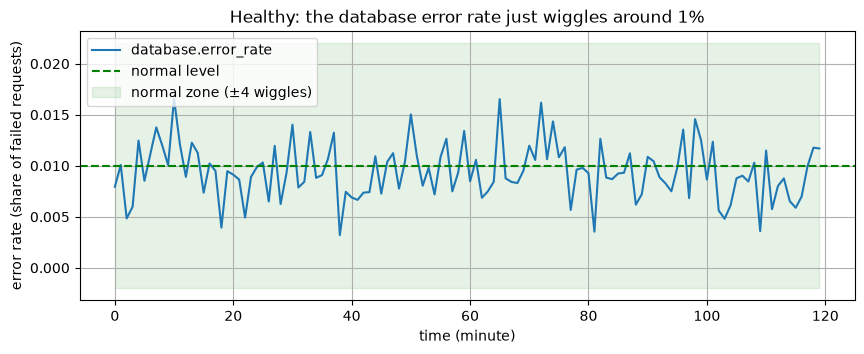

In [4]:
col = "database.error_rate"
mean, noise = NORMAL["error_rate"]

fig, ax = plt.subplots()
ax.plot(table.index, table[col], label=col)
ax.axhline(mean, color="green", linestyle="--", label="normal level")
ax.fill_between(
    table.index,
    mean - 4 * noise,
    mean + 4 * noise,
    color="green",
    alpha=0.1,
    label="normal zone (±4 wiggles)",
)
ax.set_xlabel("time (minute)")
ax.set_ylabel("error rate (share of failed requests)")
ax.set_title("Healthy: the database error rate just wiggles around 1%")
ax.legend(loc="upper left")
fig.savefig("../docs/figures/01_healthy.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read it.** The x-axis is time, one point per minute. The y-axis is how many
requests failed (0.01 means 1 in 100). The line stays inside the green zone the whole
time. That's what "healthy" looks like: noise, but no trend and no jump.

You might occasionally see a single spike that pokes out for 1 or 2 minutes and then
returns. That's a **blip** (a slow garbage-collection pause, one heavy request). The
simulator adds those on purpose, because a good detector must **not** wake someone up
for a blip.

## 4. Something breaks

Now we take the same healthy table and break the database on purpose. This is the
**before → after** step:

- **before**: the healthy table from above
- **after**: the same table, plus a fault added on top

The simulator knows four kinds of fault:

| Fault | What happens in real life | Metrics it pushes up |
|---|---|---|
| `slow_queries` | the database takes ages to answer | latency, cpu |
| `error_burst` | the service starts failing requests | error rate |
| `cpu_saturation` | the machine is overloaded | cpu, latency |
| `bad_deploy` | someone released buggy code | error rate, latency (and a deploy appears) |

We use `error_burst` on `database` with `seed=7` (a seed makes the random numbers the
same every time, so you see exactly what I see).

In [5]:
incident = make_scenario(kind="error_burst", service="database", seed=7)
truth = incident.fault
print("the hidden truth:", truth)

the hidden truth: Fault(kind='error_burst', service='database', start=49, severity=0.9923055319966457)


`incident.fault` is the **answer key**: which service really broke, how, at which minute
and how strongly (`severity` between 0.1 and 1). PulseOps itself never looks at it. We
only use it later to grade PulseOps, like a teacher holding the answer sheet.

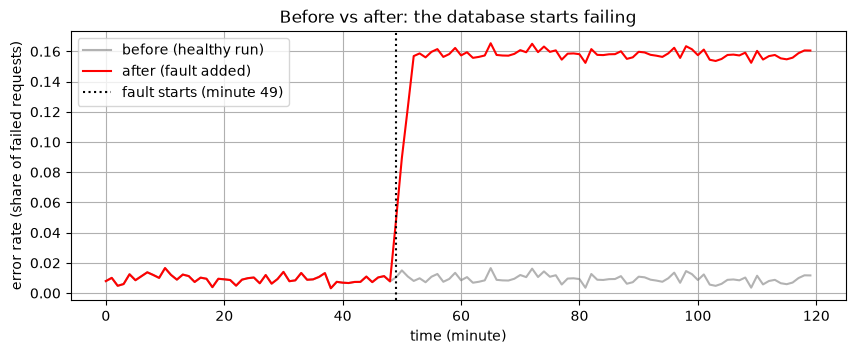

In [6]:
fig, ax = plt.subplots()
ax.plot(
    healthy.metrics.index,
    healthy.metrics[col],
    color="grey",
    alpha=0.6,
    label="before (healthy run)",
)
ax.plot(incident.metrics.index, incident.metrics[col], color="red", label="after (fault added)")
ax.axvline(truth.start, color="black", linestyle=":", label=f"fault starts (minute {truth.start})")
ax.set_xlabel("time (minute)")
ax.set_ylabel("error rate (share of failed requests)")
ax.set_title("Before vs after: the database starts failing")
ax.legend(loc="upper left")
fig.savefig("../docs/figures/02_before_after.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read it.** Grey is the healthy run, red is the broken one. Before the dotted
line they behave the same. After it, the red line climbs over a few minutes (problems
rarely appear instantly; this is the **ramp**) and then stays high. Unlike a blip, it
**does not come back down**. That difference, "far from normal *and* stays there", is
exactly what the detector looks for.

## 5. The domino effect

Here is the real headache. The database broke, but who else looks sick?

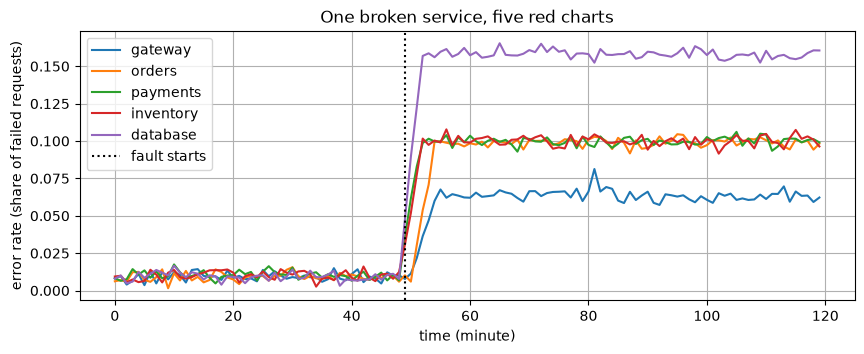

In [7]:
fig, ax = plt.subplots()
for service in SERVICES:
    ax.plot(incident.metrics[f"{service}.error_rate"], label=service)
ax.axvline(truth.start, color="black", linestyle=":", label="fault starts")
ax.set_xlabel("time (minute)")
ax.set_ylabel("error rate (share of failed requests)")
ax.set_title("One broken service, five red charts")
ax.legend(loc="upper left")
fig.savefig("../docs/figures/03_domino.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read it.** All five services go up around the same minute. The database is the
highest, because it's the real problem. Payments and inventory call the database
directly, so they get a weaker copy. Orders and gateway are further away and get an even
weaker copy, sometimes a minute or two later.

In the simulator each step away keeps 60% of the strength (`0.6 ** hops`) and adds 0 to
2 minutes of delay. An on-call engineer would see five alarms at once. PulseOps's job
is to point at the database.

CPU does not spread: if the database machine is overloaded, the gateway's machine is not.
That's why only latency and error rate travel along the arrows.

## 6. All four fault kinds at a glance

Each picture shows the broken service's main metric, healthy (grey) vs broken (red).

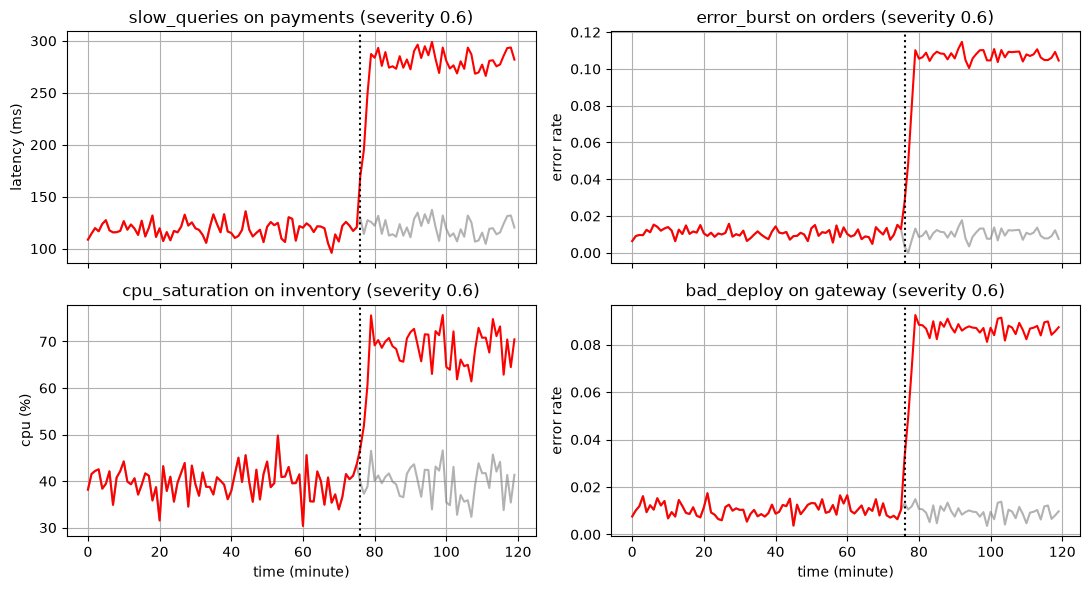

In [8]:
examples = [
    ("slow_queries", "payments", "latency_ms", "latency (ms)"),
    ("error_burst", "orders", "error_rate", "error rate"),
    ("cpu_saturation", "inventory", "cpu", "cpu (%)"),
    ("bad_deploy", "gateway", "error_rate", "error rate"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (kind, service, metric, ylabel) in zip(axes.flat, examples, strict=True):
    seed = 3
    before = make_scenario(kind=None, seed=seed).metrics
    after = make_scenario(kind=kind, service=service, seed=seed)
    name = f"{service}.{metric}"
    ax.plot(before[name], color="grey", alpha=0.6)
    ax.plot(after.metrics[name], color="red")
    ax.axvline(after.fault.start, color="black", linestyle=":")
    ax.set_title(f"{kind} on {service} (severity {after.fault.severity:.1f})")
    ax.set_ylabel(ylabel)
for ax in axes[1]:
    ax.set_xlabel("time (minute)")
fig.tight_layout()
fig.savefig("../docs/figures/04_fault_kinds.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read it.** The severity in each title is random. A strong fault (close to 1)
is obvious; a weak one (close to 0.1) barely rises above the noise. Weak faults are
included on purpose, because they are the ones that get missed, and the evaluation
should show that honestly.

For `bad_deploy`, the simulator also writes a **deploy event** a few minutes before the
fault. That's a second kind of data, which we look at next.

## 7. The second kind of data: deploys

Besides the metrics table, every scenario has a short list of **deploys**: "service X
released new code at minute N". Most are harmless (people deploy all the time). Only in
`bad_deploy` is one of them guilty.

In [9]:
bad = make_scenario(kind="bad_deploy", service="gateway", seed=3)
print("deploys:", bad.deploys)
print("truth:  ", bad.fault)

deploys: [Deploy(service='gateway', step=74)]
truth:   Fault(kind='bad_deploy', service='gateway', start=76, severity=0.6466889537273405)


## 8. How the simulator builds a scenario (the recipe)

Every scenario is made in four steps. All of it lives in `src/pulseops/simulator.py`.

1. **Healthy base.** For each of the 15 columns, draw 120 random numbers around the
   normal level (`normal_metrics`). Sometimes add a 1 to 2 minute blip.
2. **Random deploys.** Add 0 to 2 harmless deploys (`random_deploys`).
3. **Pick a fault.** Kind, service, start minute (45 to 89) and severity (0.1 to 1).
4. **Add the fault on top** (`inject_fault`): ramp up over 3 to 9 minutes on the broken
   service, then copy a weaker, later version to everyone who calls it.

You can do steps 1 and 4 by hand to see the before/after yourself:

In [10]:
import numpy as np

from pulseops.simulator import Fault

rng = np.random.default_rng(0)
before = normal_metrics(rng)
after = before.copy()
inject_fault(after, Fault(kind="slow_queries", service="database", start=60, severity=1.0), rng)

pd.DataFrame(
    {
        "before": before["database.latency_ms"],
        "after": after["database.latency_ms"],
    }
).iloc[56:72].round(1)

,before,after
56,124.1,124.1
57,112.0,112.0
58,124.1,124.1
59,118.2,118.2
60,116.3,152.0
61,113.3,184.7
62,119.8,226.9
63,119.5,262.4
64,116.8,295.4
65,108.9,323.2


Minutes 56 to 59 are the same in both columns. From minute 60 the "after" column climbs
step by step (the ramp) until it's about 250 ms above normal. That's the whole trick: a
fault is just numbers **added on top** of a healthy table.

## 9. Where would this data come from in a real company?

We made the data ourselves. Why not use real data?

- Companies don't publish their incident data.
- Even when you have real data, nobody wrote down the exact root cause of each incident,
  so you can't grade the tool. With a simulator, we always have the answer key.

In a real setup (this is the **next phase, not built yet**), the same table would come
from a monitoring system:

| Step | Real world | Our version |
|---|---|---|
| services expose numbers | each service has a `/metrics` page | `normal_metrics()` |
| something collects them | **Prometheus** reads every page every 15 s and stores it | the DataFrame |
| we read them back | Prometheus query API, one query per metric | `scenario.metrics` |
| deploys | CI/CD tool (GitHub Actions, Argo CD) logs each release | `scenario.deploys` |
| answer key | postmortem written after the incident (if anyone wrote one) | `scenario.fault` |

For example, the real error rate for one service would be a Prometheus query like
`rate(http_requests_total{status=~"5.."}[1m]) / rate(http_requests_total[1m])`
(failed requests per second divided by all requests per second). Turn the answer into a
table with one row per minute and one column per `service.metric`, and the rest of
PulseOps works the same.

## 10. Save the data as CSV

Last step: write the tables to files so you can open them in Excel or use them anywhere
else. Each file has a `minute` column plus the 15 metric columns. A small `labels.csv`
holds the answer key for every incident file.

In [11]:
from pathlib import Path

out = Path("../data")
out.mkdir(exist_ok=True)

healthy.metrics.rename_axis("minute").round(4).to_csv(out / "healthy.csv")

labels = []
for kind in ["slow_queries", "error_burst", "cpu_saturation", "bad_deploy"]:
    s = make_scenario(kind=kind, service="database", seed=7)
    name = f"{kind}_database.csv"
    s.metrics.rename_axis("minute").round(4).to_csv(out / name)
    labels.append(
        {
            "file": name,
            "kind": kind,
            "root_cause": s.fault.service,
            "start_minute": s.fault.start,
            "severity": round(s.fault.severity, 2),
            "deploys": "; ".join(f"{d.service}@{d.step}" for d in s.deploys),
        }
    )

pd.DataFrame(labels).to_csv(out / "labels.csv", index=False)
print(sorted(p.name for p in out.glob("*.csv")))
pd.DataFrame(labels)

['bad_deploy_database.csv', 'cpu_saturation_database.csv', 'error_burst_database.csv', 'healthy.csv', 'labels.csv', 'slow_queries_database.csv']

,file,kind,root_cause,start_minute,severity,deploys
0,slow_queries_database.csv,slow_queries,database,49,0.99,payments@106
1,error_burst_database.csv,error_burst,database,49,0.99,payments@106
2,cpu_saturation_database.csv,cpu_saturation,database,49,0.99,payments@106
3,bad_deploy_database.csv,bad_deploy,database,49,0.99,payments@106; database@45


## Recap

- The data is a table: **120 minutes × 15 columns** (5 services × latency, errors, CPU).
- **Healthy** = numbers wiggle around a normal level, with the occasional short blip.
- **Incident** = one service's numbers ramp up and **stay** up; services that call it get
  a weaker, slightly later copy (the domino effect).
- We generate it ourselves so we always know the true root cause and can **measure**
  PulseOps. In a real company it would come from Prometheus; that's the next phase.
- Files: `data/healthy.csv`, `data/<fault>_database.csv`, `data/labels.csv`.

Next: `scripts/debug_flow.py` shows what PulseOps does with this table, step by step.